# Part 1: Linear Regression

## Getting started

We begin our study of linear models with linear regression. In this notebook we will compare a direct least-squares solution with a hand-written gradient descent implementation, first on synthetic data and then on a real dataset.

The tensor indexing, matrix multiplication, and plotting used below build on Lab 1.

In [1]:
import torch

torch.manual_seed(0)

# Generate some data points on a straight line perturbed with Gaussian noise
N = 1000 # number of points
theta_true = torch.Tensor([[1.5], [2.0]]) # true parameters of the line

X = torch.rand(N, 2)
X[:, 1] = 1.0
y = X @ theta_true + 0.1 * torch.randn(N, 1) # Note that just like in numpy '@' represents matrix multiplication and A@B is equivalent to torch.mm(A, B)

The above code generates $(x,y)$ data according to $y = 1.5x + 2$, with the $x$'s chosen from a uniform distribution. The $y$'s are additionally perturbed by adding an amount $0.1z$, where $z\sim \mathcal{N}(0,1)$ is a sample from a standard normal distribution.

Note that we represent our $x$'s as a two-dimensional (row) vector with a 1 in the second element so that the offset can be rolled into the matrix multiplication for efficiency:

\begin{align}
    y &= \mathbf{X}\begin{bmatrix}
           1.5 \\
           2
         \end{bmatrix}
  \end{align}

Let's use `matplotlib` to draw a scatter so we can be sure of what our data looks like:

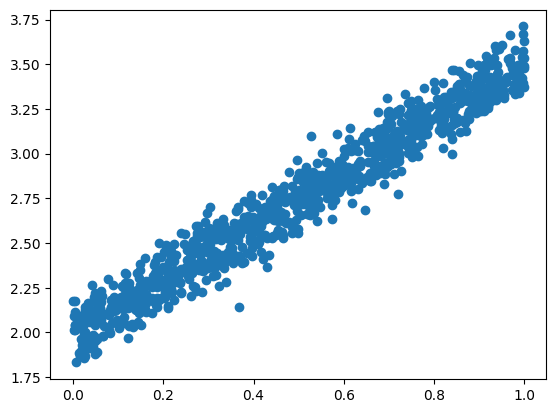

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.scatter(X[:,0].numpy(), y.numpy())
plt.show()

__Make sure you understand how the code above is generating data; feel free to change the parameters to see what effect they have.__

Now, lets consider the situation where we have been given the tensors $X$ and $y$ and wish to compute the regression parameters. Our model looks like $\mathbf{y} = \mathbf{X\theta}$, and we wish to recover the parameters $\theta$.

As the problem is both overdetermined (only two data pairs are required to find $\theta$), and the data is noisy, we can use the Moore-Penrose Pseudoinverse to find the least-squares solution to $\theta$: $\theta = \mathbf{X^+y}$. PyTorch has a built-in pseudoinverse method (`torch.linalg.pinv`) that can do all the work for us:

In [3]:
# direct solution using moore-penrose pseudo inverse
X_inv = torch.linalg.pinv(X)
theta_pinv = torch.mm(X_inv, y)
print(theta_pinv)

tensor([[1.5056],
        [1.9945]])


Running the above code should give you a solution vector for $\theta$ that is very similar to the true parameter vector (`theta_true`).

## Exercise: computing the pseudoinverse from the Singular Value Decomposition

The standard way of computing the pseudoinverse is by using the Singular Value Decomposition (SVD). For the reduced SVD, $\mathbf{X}=\mathbf{U}\Sigma\mathbf{V}^{\mathsf T}$, and

$$
\mathbf{X}^+ = \mathbf{V}\Sigma^{-1}\mathbf{U}^{\mathsf T},
$$

where $\Sigma^{-1}$ contains the reciprocals of the non-zero singular values.

__Use the code block below to compute the parameter vector directly from the SVD rather than through `torch.linalg.pinv`.__ Store the manually computed pseudoinverse in `X_inv_svd`. Use `torch.linalg.svd(X, full_matrices=False)`; it returns `U`, the singular values `S`, and `Vh` (which is $\mathbf V^{\mathsf T}$).

In [4]:
# YOUR CODE HERE
U, S, Vh = torch.linalg.svd(X, full_matrices=False)
X_inv_svd = Vh.t() @ torch.diag(1.0 / S) @ U.t()

theta_pinv_svd = torch.mm(X_inv_svd, y)
print(theta_pinv_svd)

tensor([[1.5056],
        [1.9945]])


In [5]:
assert(torch.all(torch.lt(torch.abs(torch.add(theta_pinv, -theta_pinv_svd)), 1e-6)))

## Gradient based Linear Regression

Fundamentally, with linear regression we are trying to find a solution vector, $\theta$ that minimises $f(\theta) = 0.5\|\mathbf{X}\theta - \mathbf{y}\|_2^2$.

We've already seen how this can be minimised directly using the pseudoinverse, but it could also be minimised by using gradient descent: $\theta \gets \theta - \alpha f'(\theta)$. (_Interesting aside_: SVD (and thus the pseudoinverse) can also be solved using gradient methods - in fact this becomes the only practical way for really large matrices.).

__Use the following block to derive and write down the gradient, $f'(\theta)$, of $f(\theta)$__. Note that you can insert latex code by wrapping expressions in dollar symbols.

$f(\theta) = \tfrac{1}{2}\|\mathbf{X}\theta - \mathbf{y}\|_2^2 = \tfrac{1}{2}(\mathbf{X}\theta - \mathbf{y})^\top(\mathbf{X}\theta - \mathbf{y})$

Expanding: $f(\theta) = \tfrac{1}{2}\left(\theta^\top \mathbf{X}^\top\mathbf{X}\theta - 2\theta^\top\mathbf{X}^\top\mathbf{y} + \mathbf{y}^\top\mathbf{y}\right)$

Differentiating with respect to $\theta$ (using $\mathbf{X}^\top\mathbf{X}$ symmetric):

$f'(\theta) = \mathbf{X}^\top\mathbf{X}\theta - \mathbf{X}^\top\mathbf{y} = \mathbf{X}^\top(\mathbf{X}\theta - \mathbf{y})$

__Now complete the following code block to implement your gradient as pytorch code:__

In [6]:
def linear_regression_loss_grad(theta, X, y):
    # theta, X and y have the same shape as used previously
    grad = X.t() @ (X @ theta - y)
    return grad

In [7]:
assert(linear_regression_loss_grad(torch.zeros(2,1), X, y).shape == (2,1))


Now we can plug that gradient function into a basic gradient descent solver and check that the solution is close to what we get with the pseudoinverse:

In [8]:
alpha = 0.001
theta = torch.Tensor([[0], [0]])
for e in range(0, 200):
    gr = linear_regression_loss_grad(theta, X, y)
    theta -= alpha * gr

print(theta)

tensor([[1.5056],
        [1.9945]])


## Real data

Doing linear regression on synthetic data is a great way to understand how PyTorch works, but it isn't quite as satisfying as working with a real dataset. Let's now apply our understanding of computing linear regression parameters to a dataset of Diabetes.

We'll load the dataset using scikit-learn and perform some manipulations in the following code block:

In [9]:
from sklearn.datasets import load_diabetes

Data = tuple(torch.Tensor(z) for z in load_diabetes(return_X_y=True)) #convert to pytorch Tensors
X, y = Data[0], Data[1]
X = torch.cat((X, torch.ones((X.shape[0], 1))), 1) # append a column of 1's to the X's
y = y.reshape(-1, 1) # reshape y into a column vector
print('X:', X.shape)
print('y:', y.shape)

# We're also going to break the data into a training set for computing the regression parameters
# and a test set to evaluate the predictive ability of those parameters
perm = torch.randperm(y.shape[0])
X_train = X[perm[0:253], :]  # note the ", :" is optional - we just want to highlight that X is a matrix whereas y is a vector
y_train = y[perm[0:253]]
X_test = X[perm[253:], :]
y_test = y[perm[253:]]

X: torch.Size([442, 11])
y: torch.Size([442, 1])


__Use the following code block to compute the regression parameters using the training data in the variable `theta` by solving using the pseudoinverse directly (using `torch.linalg.pinv` like you did above):__

In [10]:
# compute the regression parameters in variable theta
theta = torch.linalg.pinv(X_train) @ y_train

We can now print out the error achieved on the test set, as well as the parameter vector:

In [11]:
assert(theta.shape == (11,1))

print("Theta: ", theta.t())
print("MSE of test data: ", torch.nn.functional.mse_loss(X_test @ theta, y_test))

Theta:  tensor([[  25.9232, -208.1991,  521.4875,  381.5514, -872.4979,  403.5159,
          278.9241,  382.1591,  756.5430,   34.3110,  148.2785]])
MSE of test data:  tensor(3015.9216)


Now let's try using gradient descent:

In [12]:
alpha = 0.00001
theta_gd = torch.rand((X_train.shape[1], 1))
for e in range(0, 10000):
    gr = linear_regression_loss_grad(theta_gd, X_train, y_train)
    theta_gd -= alpha * gr

print("Gradient Descent Theta: ", theta_gd.t())
print("MSE of test data: ", torch.nn.functional.mse_loss(X_test @ theta_gd, y_test))

Gradient Descent Theta:  tensor([[ 15.3465,   0.3499,  49.8003,  36.3584,  16.9882,  11.2190, -29.7693,
          31.7602,  49.5408,  30.7278, 149.4570]])
MSE of test data:  tensor(5171.9043)


__Use the following block to note down any observations you can make about the choice of learning rate and number of iterations in the above code. What factors do you think influence the choice?__

With $\alpha = 10^{-5}$ and 10,000 iterations, gradient descent hasn't converged. The test MSE is clearly worse than the pseudoinverse solution (roughly 5000 vs 3000 in my run). The bias term converges to about the mean of $y$ (~150), but the feature weights barely move from their random starting values.

The reason is that the diabetes features are already mean-centred and scaled to small values, so the gradient with respect to the feature weights is tiny compared with the gradient for the bias column of 1s. The problem is badly conditioned: the eigenvalues of $\mathbf{X}^\top\mathbf{X}$ range from about $3\times10^{-3}$ up to about $250$.

The factors that influence the choice:
- **Stability:** $\alpha$ must be below $2/\lambda_{\max}(\mathbf{X}^\top\mathbf{X})$ (about 0.008 here) or the updates diverge. I tried $\alpha = 10^{-2}$ and it blew up to NaN.
- **Speed:** the slowest direction converges at a rate set by $\lambda_{\min}$, so the number of iterations needed grows with the condition number $\lambda_{\max}/\lambda_{\min}$.
- **Data scaling and size:** feature scaling and the number of training points (the gradient is a sum, not a mean) change the eigenvalues.
- **Initialisation and stopping criterion.**

Raising $\alpha$ to $10^{-3}$ brings the test MSE close to the pinv solution within the same 10,000 iterations. Standardising the features, or using a mean rather than a sum in the loss, would also make picking $\alpha$ easier.

Finally, just so we can visualise what our model has learned, we can plot the quantitative measure of disease progression (from both the direct solution and from gradient descent) along with the true value for each of the patient number in the test set (ordered by increasing true value):

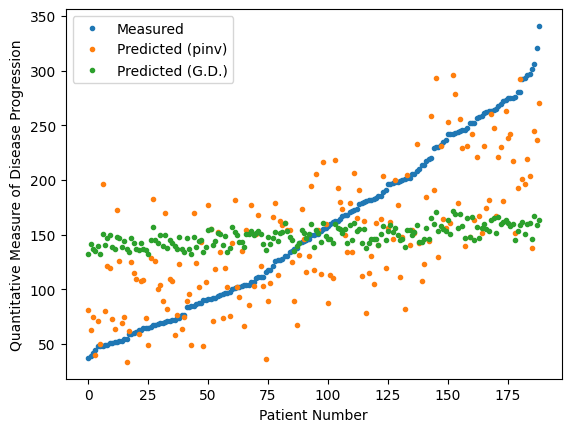

In [13]:
perm = torch.argsort(y_test, dim=0)
plt.plot(y_test[perm[:,0]].numpy(), '.', label='Measured')
plt.plot((X_test[perm[:,0]] @ theta).numpy(), '.', label='Predicted (pinv)')
plt.plot((X_test[perm[:,0]] @ theta_gd).numpy(), '.', label='Predicted (G.D.)')
plt.xlabel('Patient Number')
plt.ylabel('Quantitative Measure of Disease Progression')
plt.legend()
plt.show()